In [2]:
# Connect Google Drive to Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
dataset_path = '/content/drive/MyDrive/Dataset.csv'

In [4]:
# Install required libraries

!pip install pandas numpy matplotlib seaborn plotly

In [5]:
# Import Python libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load Netflix dataset from Google Drive

dataset_path = '/content/drive/MyDrive/Dataset.csv'
df = pd.read_csv(dataset_path)

# Display first five records

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [7]:
# Display dataset information

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

print("\nColumn Names:")

print(df.columns.tolist())

print("\nDataset Information:")

df.info()

Total Rows: 8790
Total Columns: 10

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [8]:
# Create main project folder
project_path = '/content/drive/MyDrive/Netflix_Data_Analysis'
os.makedirs(project_path, exist_ok=True)

# Create folders for six tasks
tasks = [
    'Task_01_Data_Cleaning',
    'Task_02_Content_Analysis',
    'Task_03_Country_Analysis',
    'Task_04_Trend_Analysis',
    'Task_05_Rating_Genre_Analysis',
    'Task_06_Business_Insights'
]

for task in tasks:

    os.makedirs(os.path.join(project_path, task), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


# **TASK 01 - Clean and prepare the Netflix dataset for further analysis.**

In [9]:
# Display first 10 records
df.head(10)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [10]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")

print(missing_values)

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [11]:
# Calculate total missing values
total_missing = df.isnull().sum().sum()

print("Total Missing Values:", total_missing)

Total Missing Values: 0


In [12]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [13]:
# Check data types
print(df.dtypes)

show_id         object
type            object
title           object
director        object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
dtype: object


In [14]:
# Standardize text columns
text_columns = [
    'type',
    'title',
    'director',
    'country',
    'rating',
    'duration',
    'listed_in'
]

for column in text_columns:

    df[column] = df[column].str.strip()

# Standardize content type

df['type'] = df['type'].str.title()

print("Text formatting completed!")

Text formatting completed!


In [15]:
# Convert date_added into datetime format
df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

print(df['date_added'].dtype)

datetime64[ns]


In [16]:
# Check final dataset
print("Dataset Shape:", df.shape)

print("\nMissing Values:")

print(df.isnull().sum())

print("\nDuplicate Records:")

print(df.duplicated().sum())

Dataset Shape: (8790, 10)

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Records:
0


In [17]:
# Save cleaned dataset to Google Drive

cleaned_path = os.path.join(
    project_path,
    'Task_01_Data_Cleaning',
    'netflix_cleaned.csv'
)

df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved successfully!")

print(cleaned_path)

Cleaned dataset saved successfully!
/content/drive/MyDrive/Netflix_Data_Analysis/Task_01_Data_Cleaning/netflix_cleaned.csv


# **TASK 02 Content Type Analysis Dashboard.**

In [18]:
# Load cleaned dataset
df = pd.read_csv(cleaned_path)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [19]:
# Count Movies and TV Shows
content_counts = df['type'].value_counts()

print("Netflix Content Distribution:")

print(content_counts)

Netflix Content Distribution:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


In [20]:
# Calculate content percentages
total_content = len(df)

content_percentage = (
    content_counts / total_content
) * 100

print("Content Percentages:")

print(content_percentage.round(2))

Content Percentages:
type
Movie      69.69
Tv Show    30.31
Name: count, dtype: float64


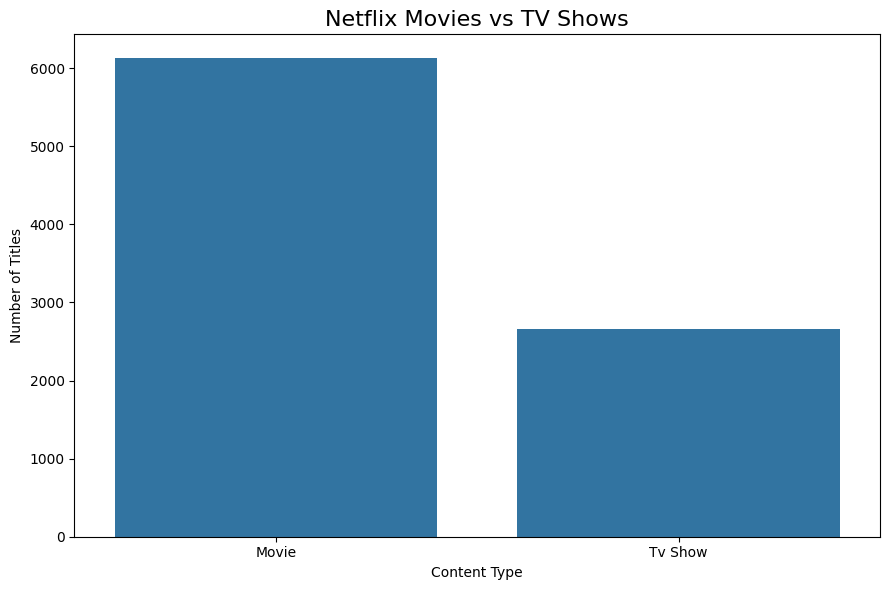

In [22]:
# Movies vs TV Shows Bar Chart
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x='type'
)

plt.title(
    'Netflix Movies vs TV Shows',
    fontsize=16
)

plt.xlabel('Content Type')

plt.ylabel('Number of Titles')

plt.tight_layout()

plt.savefig(
    os.path.join(
        project_path,
        'Task_02_Content_Analysis',
        'content_bar_chart.png'
    )
)

plt.show()

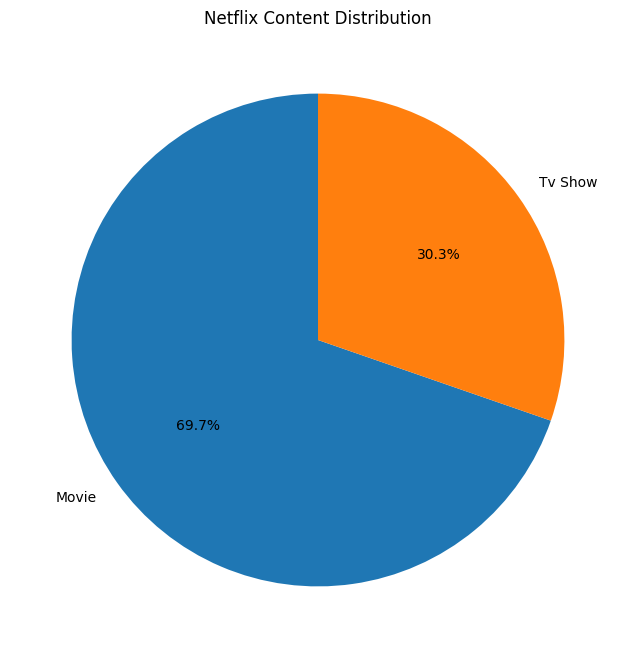

In [23]:
# Content Distribution Pie Chart
plt.figure(figsize=(8, 8))

plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Netflix Content Distribution')

plt.savefig(
    os.path.join(
        project_path,
        'Task_02_Content_Analysis',
        'content_pie_chart.png'
    )
)

plt.show()

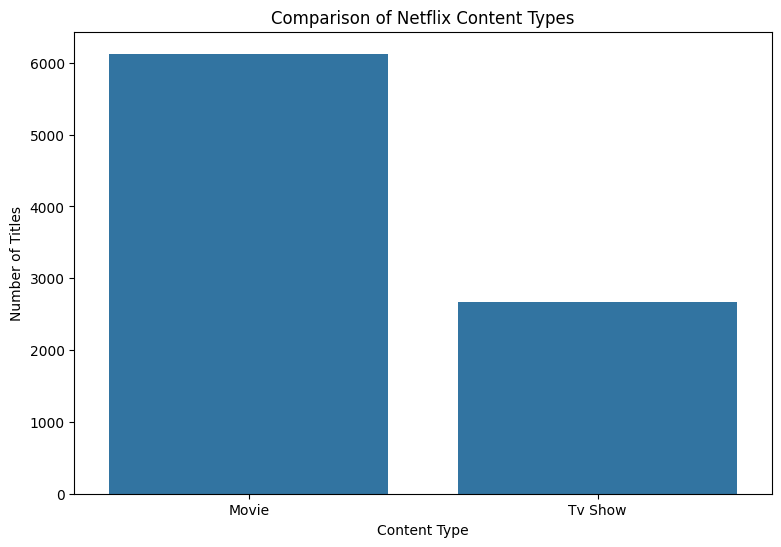

In [24]:
# Compare Movies and TV Shows
plt.figure(figsize=(9, 6))

sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title('Comparison of Netflix Content Types')

plt.xlabel('Content Type')

plt.ylabel('Number of Titles')

plt.show()

In [25]:
# Generate automatic findings
most_common = content_counts.idxmax()

highest_count = content_counts.max()

highest_percentage = content_percentage.max()

print("CONTENT ANALYSIS FINDINGS")

print("--------------------------")

print("Total Content:", total_content)

print("Most Common Content:", most_common)

print("Number of Titles:", highest_count)

print(
    "Percentage:",
    round(highest_percentage, 2),
    "%"
)

CONTENT ANALYSIS FINDINGS
--------------------------
Total Content: 8790
Most Common Content: Movie
Number of Titles: 6126
Percentage: 69.69 %


# **TASK 03 - Country-Wise Netflix Content Analysis**

In [26]:
# Create a copy of the dataset
country_df = df.copy()

# Split countries
country_df['country'] = country_df['country'].str.split(',')

# Create separate rows for each country
country_df = country_df.explode('country')

# Remove unnecessary spaces
country_df['country'] = country_df['country'].str.strip()

# Remove unknown country values
country_df = country_df[
    country_df['country'].notna()
]

country_df = country_df[
    country_df['country'] != 'Not Given'
]

print("Country data prepared successfully!")

country_df.head()

Country data prepared successfully!


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [27]:
# Calculate country-wise content count
country_counts = country_df['country'].value_counts()

print(country_counts.head(20))

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             112
Nigeria            105
Germany            104
China              100
Brazil              88
Taiwan              86
Indonesia           86
Philippines         83
Name: count, dtype: int64


In [28]:
# Select top 10 countries
top_countries = country_counts.head(10)

print("TOP 10 COUNTRIES")

print(top_countries)

TOP 10 COUNTRIES
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


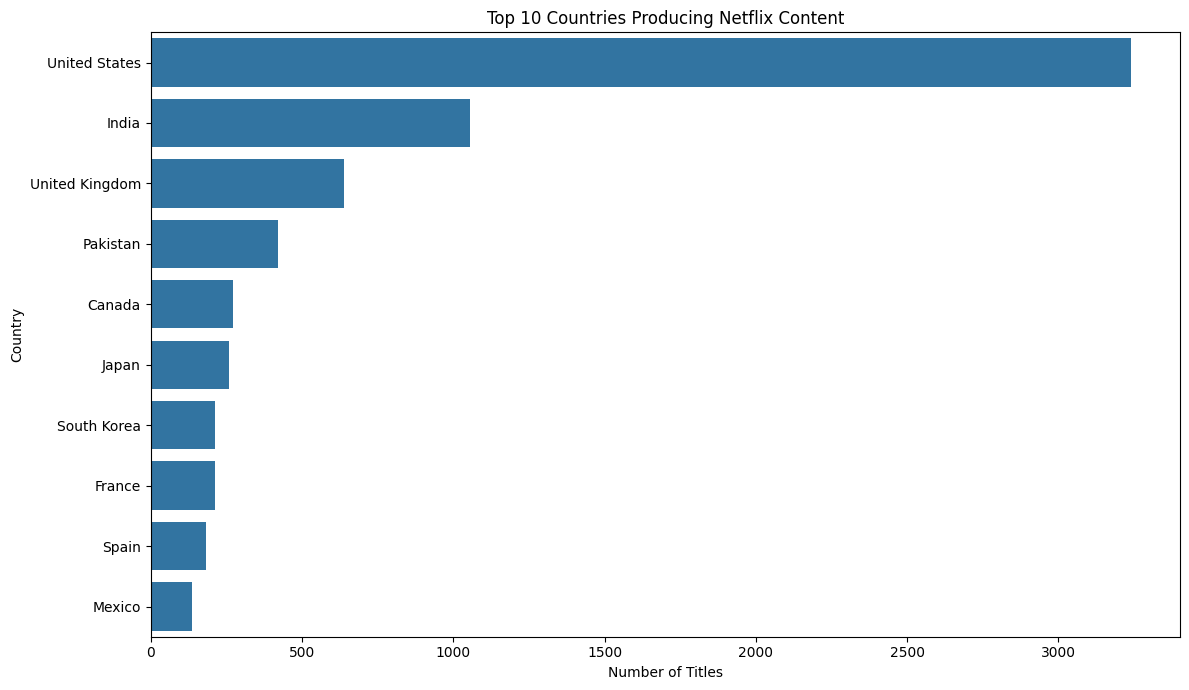

In [29]:
# Country-wise content visualization
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries Producing Netflix Content')

plt.xlabel('Number of Titles')

plt.ylabel('Country')

plt.tight_layout()

plt.savefig(
    os.path.join(
        project_path,
        'Task_03_Country_Analysis',
        'top_countries.png'
    )
)

plt.show()

In [30]:
# Create country ranking
country_ranking = top_countries.reset_index()

country_ranking.columns = [
    'Country',
    'Content Count'
]

country_ranking.index += 1

country_ranking.index.name = 'Rank'

print(country_ranking)

             Country  Content Count
Rank                               
1      United States           3240
2              India           1057
3     United Kingdom            638
4           Pakistan            421
5             Canada            271
6              Japan            259
7        South Korea            214
8             France            213
9              Spain            182
10            Mexico            138


In [31]:
# Interactive country visualization
fig = px.bar(
    top_countries,
    x=top_countries.values,
    y=top_countries.index,
    orientation='h',
    title='Top 10 Netflix Content Producing Countries',
    labels={
        'x': 'Number of Titles',
        'y': 'Country'
    }
)

fig.update_layout(
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

In [32]:
# Generate country analysis findings
top_country = country_counts.idxmax()

top_country_count = country_counts.max()

print("COUNTRY ANALYSIS FINDINGS")

print("-------------------------")

print("Total Countries:", country_counts.nunique())

print("Top Producing Country:", top_country)

print("Content Count:", top_country_count)

print("\nTop 5 Countries:")

print(country_counts.head(5))

COUNTRY ANALYSIS FINDINGS
-------------------------
Total Countries: 43
Top Producing Country: United States
Content Count: 3240

Top 5 Countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Name: count, dtype: int64


# **TASK 04 - Trend Analysis by Release Year**

In [33]:
# Convert release_year into numeric format
df['release_year'] = pd.to_numeric(
    df['release_year'],
    errors='coerce'
)

# Remove records without release year
trend_df = df.dropna(
    subset=['release_year']
).copy()

trend_df['release_year'] = (
    trend_df['release_year'].astype(int)
)

print("Release year data prepared!")

Release year data prepared!


In [34]:
# Group content by release year
yearly_content = trend_df.groupby(
    'release_year'
).size()

# Sort years
yearly_content = yearly_content.sort_index()

print(yearly_content)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Length: 74, dtype: int64


In [35]:
# Find the highest content release year
highest_year = yearly_content.idxmax()

highest_count = yearly_content.max()

print("Highest Release Year:", highest_year)

print("Number of Titles:", highest_count)

Highest Release Year: 2018
Number of Titles: 1146


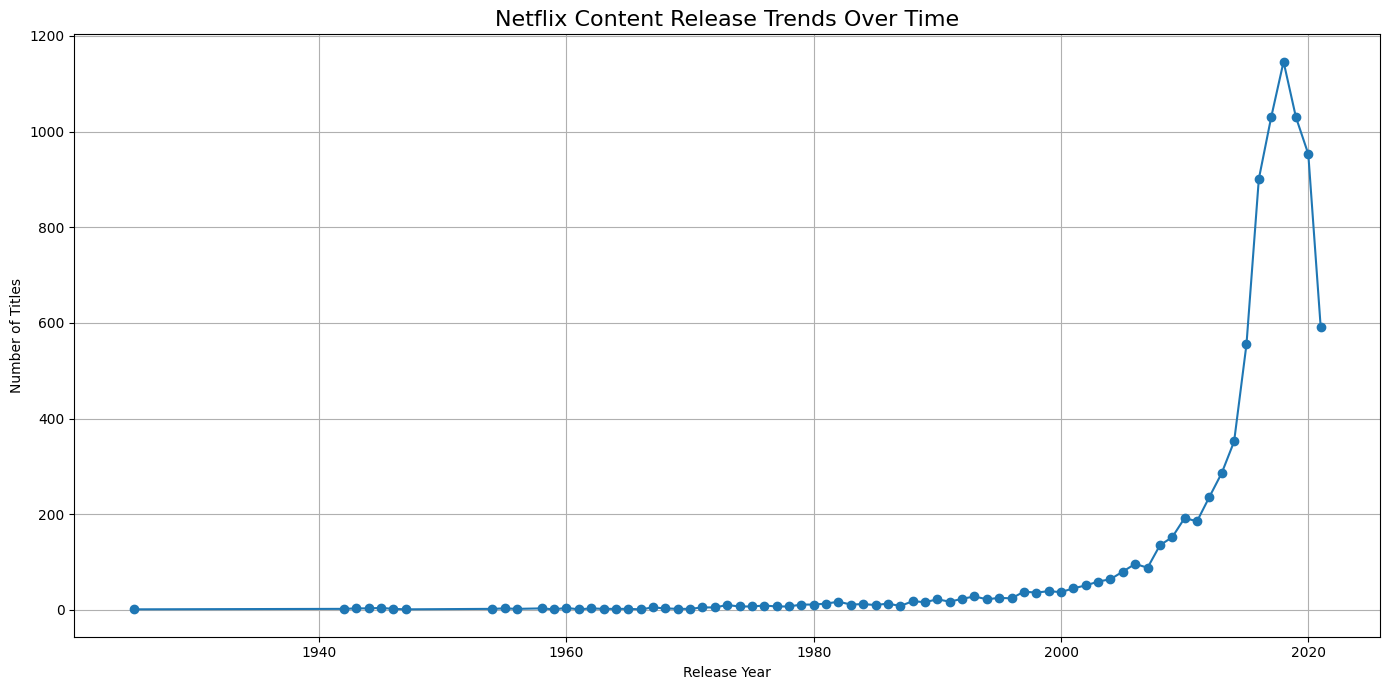

In [36]:
# Netflix Release Year Trend
plt.figure(figsize=(14, 7))

plt.plot(
    yearly_content.index,
    yearly_content.values,
    marker='o'
)

plt.title(
    'Netflix Content Release Trends Over Time',
    fontsize=16
)

plt.xlabel('Release Year')

plt.ylabel('Number of Titles')

plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        project_path,
        'Task_04_Trend_Analysis',
        'release_trend.png'
    )
)

plt.show()

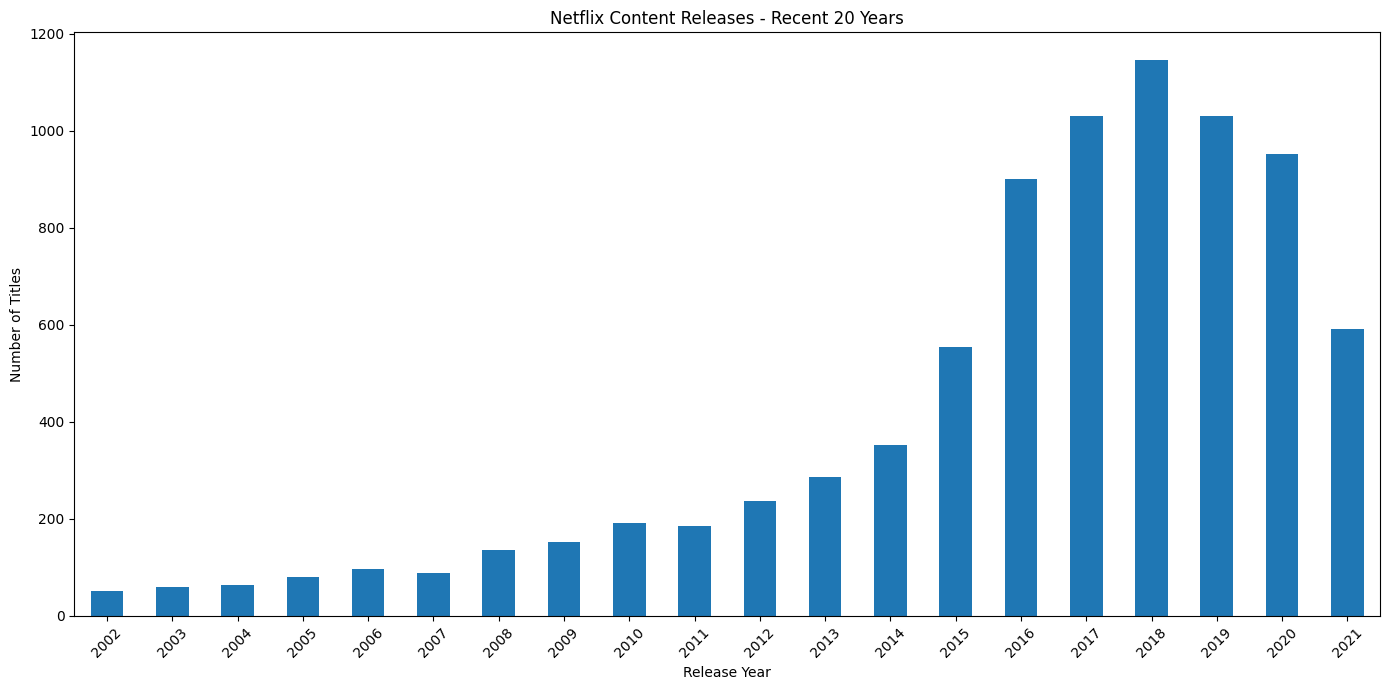

In [37]:
# Select recent 20 release years
recent_years = yearly_content.tail(20)

plt.figure(figsize=(14, 7))

recent_years.plot(kind='bar')

plt.title('Netflix Content Releases - Recent 20 Years')

plt.xlabel('Release Year')

plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

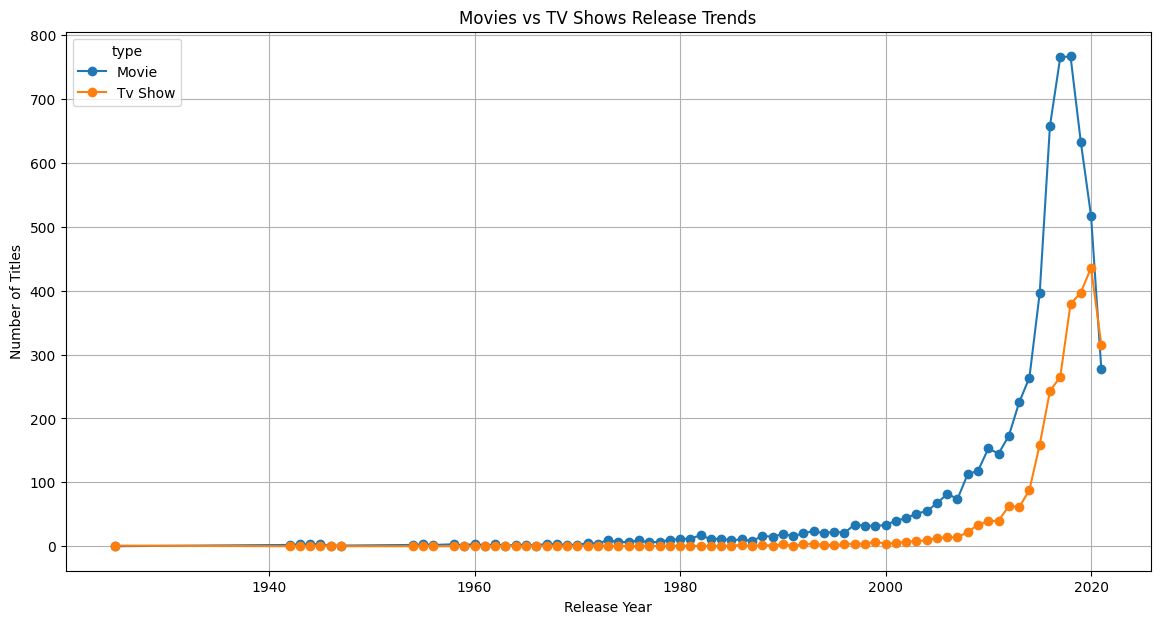

In [38]:
# Compare content types by release year
year_type = trend_df.groupby(
    ['release_year', 'type']
).size().unstack(fill_value=0)

# Plot comparison
year_type.plot(
    figsize=(14, 7),
    marker='o'
)

plt.title('Movies vs TV Shows Release Trends')

plt.xlabel('Release Year')

plt.ylabel('Number of Titles')

plt.grid(True)

plt.show()

In [39]:
# Identify highest and lowest release years
highest_year = yearly_content.idxmax()

lowest_year = yearly_content.idxmin()

print("TREND ANALYSIS FINDINGS")

print("-----------------------")

print("Highest Release Year:", highest_year)

print("Highest Content Count:", yearly_content.max())

print("Lowest Release Year:", lowest_year)

print("Lowest Content Count:", yearly_content.min())

print("\nRecent Release Data:")

print(yearly_content.tail(10))

TREND ANALYSIS FINDINGS
-----------------------
Highest Release Year: 2018
Highest Content Count: 1146
Lowest Release Year: 1925
Lowest Content Count: 1

Recent Release Data:
release_year
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
dtype: int64


# **TASK 05 - Content Rating & Genre Analysis**

***Objective: Examine content ratings and genres to understand audience targeting.***

In [40]:
# Calculate rating distribution
rating_counts = df['rating'].value_counts()

print("Netflix Rating Distribution")

print(rating_counts)

Netflix Rating Distribution
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


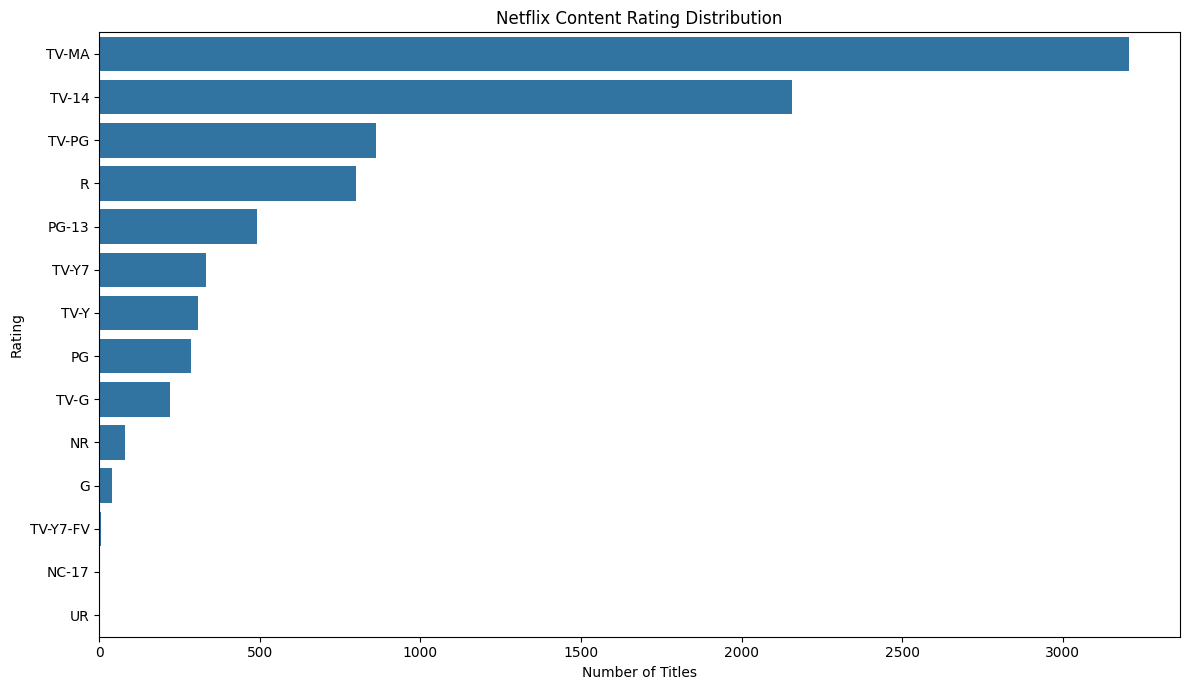

In [41]:
# Rating visualization
plt.figure(figsize=(12, 7))

sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().index
)

plt.title('Netflix Content Rating Distribution')

plt.xlabel('Number of Titles')

plt.ylabel('Rating')

plt.tight_layout()

plt.savefig(
    os.path.join(
        project_path,
        'Task_05_Rating_Genre_Analysis',
        'rating_distribution.png'
    )
)

plt.show()

In [42]:
# Create genre dataset
genre_df = df.copy()

# Split multiple genres
genre_df['listed_in'] = genre_df['listed_in'].str.split(',')

# Separate genres into rows
genre_df = genre_df.explode('listed_in')

# Remove spaces
genre_df['listed_in'] = genre_df['listed_in'].str.strip()

print(genre_df.head())

  show_id     type                 title         director        country  \
0      s1    Movie  Dick Johnson Is Dead  Kirsten Johnson  United States   
1      s3  Tv Show             Ganglands  Julien Leclercq         France   
1      s3  Tv Show             Ganglands  Julien Leclercq         France   
1      s3  Tv Show             Ganglands  Julien Leclercq         France   
2      s6  Tv Show         Midnight Mass    Mike Flanagan  United States   

   date_added  release_year rating  duration               listed_in  
0  2021-09-25          2020  PG-13    90 min           Documentaries  
1  2021-09-24          2021  TV-MA  1 Season          Crime TV Shows  
1  2021-09-24          2021  TV-MA  1 Season  International TV Shows  
1  2021-09-24          2021  TV-MA  1 Season   TV Action & Adventure  
2  2021-09-24          2021  TV-MA  1 Season               TV Dramas  


In [43]:
# Calculate genre distribution
genre_counts = genre_df['listed_in'].value_counts()

print("Top 20 Netflix Genres")

print(genre_counts.head(20))

Top 20 Netflix Genres
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Thrillers                    577
TV Comedies                  573
Crime TV Shows               469
Kids' TV                     448
Docuseries                   394
Music & Musicals             375
Romantic TV Shows            370
Horror Movies                357
Stand-Up Comedy              343
Reality TV                   255
Name: count, dtype: int64


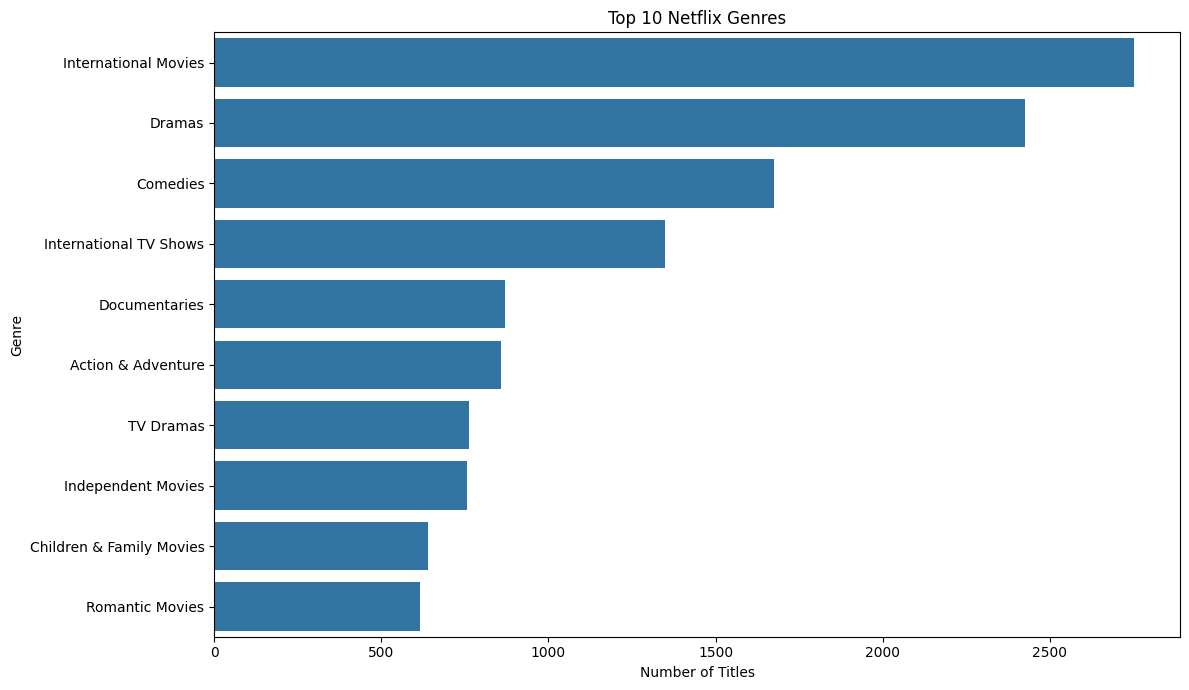

In [44]:
# Select top 10 genres
top_genres = genre_counts.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Netflix Genres')

plt.xlabel('Number of Titles')

plt.ylabel('Genre')

plt.tight_layout()

plt.savefig(
    os.path.join(
        project_path,
        'Task_05_Rating_Genre_Analysis',
        'top_genres.png'
    )
)

plt.show()

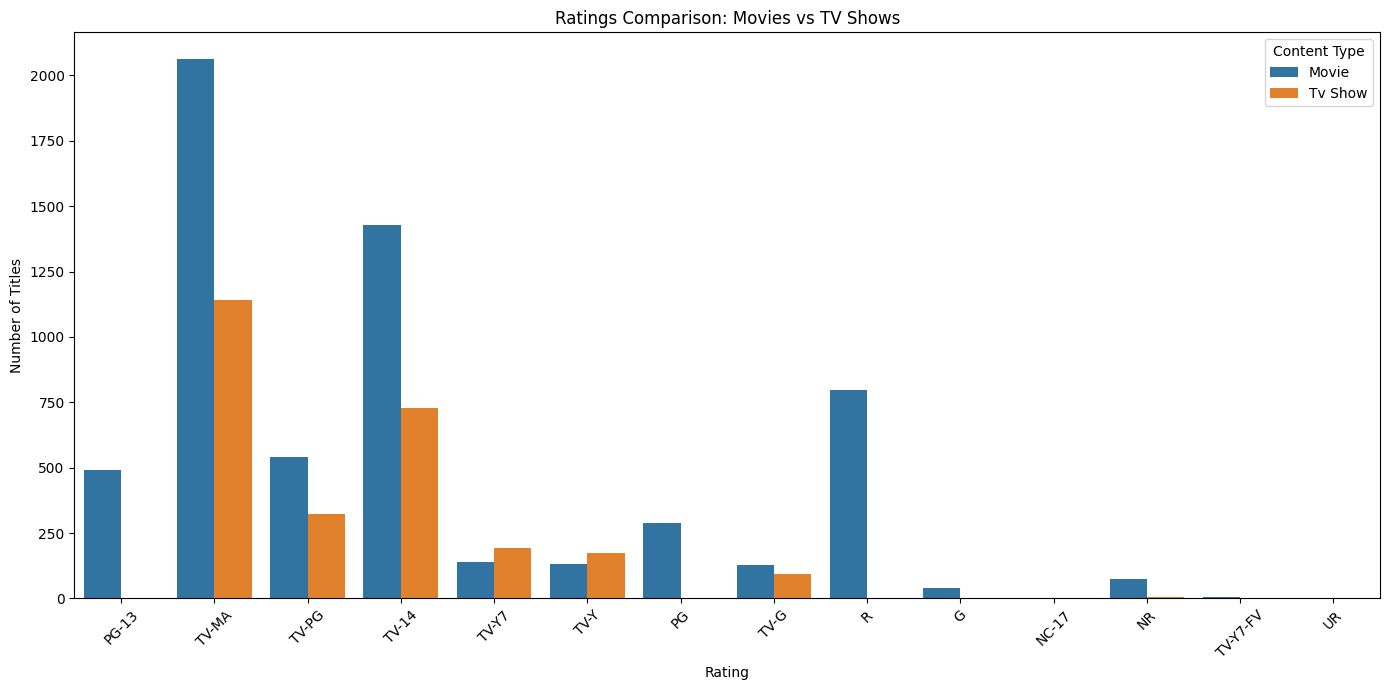

In [45]:
# Rating comparison between Movies and TV Shows
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    x='rating',
    hue='type'
)

plt.title('Ratings Comparison: Movies vs TV Shows')

plt.xlabel('Rating')

plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.legend(title='Content Type')

plt.tight_layout()

plt.show()

In [46]:
# Create rating and content type comparison
rating_comparison = pd.crosstab(
    df['rating'],
    df['type']
)

print(rating_comparison)

type      Movie  Tv Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


In [47]:
# Interactive genre visualization
fig = px.bar(
    x=top_genres.values,
    y=top_genres.index,
    orientation='h',
    title='Interactive Netflix Genre Analysis',
    labels={
        'x': 'Number of Titles',
        'y': 'Genre'
    }
)

fig.show()

In [48]:
# Interactive rating visualization
fig = px.pie(
    values=rating_counts.values,
    names=rating_counts.index,
    title='Netflix Content Rating Distribution'
)

fig.show()

In [49]:
# Generate rating and genre findings
most_common_rating = rating_counts.idxmax()

most_common_genre = genre_counts.idxmax()

print("RATING AND GENRE ANALYSIS")

print("-------------------------")

print("Most Common Rating:", most_common_rating)

print("Rating Count:", rating_counts.max())

print("\nMost Common Genre:", most_common_genre)

print("Genre Count:", genre_counts.max())

print("\nTop 5 Genres:")

print(genre_counts.head(5))

RATING AND GENRE ANALYSIS
-------------------------
Most Common Rating: TV-MA
Rating Count: 3205

Most Common Genre: International Movies
Genre Count: 2752

Top 5 Genres:
listed_in
International Movies      2752
Dramas                    2426
Comedies                  1674
International TV Shows    1349
Documentaries              869
Name: count, dtype: int64


# **TASK 06 - Netflix Business Insights Report**

In [50]:
# Complete Exploratory Data Analysis
print("NETFLIX DATASET EXPLORATORY ANALYSIS")

print("------------------------------------")

# Dataset shape
print("\nDataset Shape:")

print(df.shape)

# Dataset information
print("\nDataset Information:")

df.info()

# Statistical summary
print("\nStatistical Summary:")

print(df.describe())

# Missing values
print("\nMissing Values:")

print(df.isnull().sum())

# Duplicate values
print("\nDuplicate Records:")

print(df.duplicated().sum())

# Content types
print("\nContent Types:")

print(df['type'].value_counts())

# Ratings
print("\nRatings:")

print(df['rating'].value_counts())

# Release years
print("\nRelease Years:")

print(df['release_year'].describe())

NETFLIX DATASET EXPLORATORY ANALYSIS
------------------------------------

Dataset Shape:
(8790, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

Statistical Summary:
       release_year
count   8790.000000
mean    2014.183163
std        8.825466
min     1925.000000
25%     2013.000000
50%     2017.000000
75%     2019.000000
max     2021.000000

Missing Val

In [51]:
# Calculate Business KPIs
total_titles = len(df)

total_movies = len(
    df[df['type'] == 'Movie']
)

total_tv_shows = len(
    df[df['type'] == 'TV Show']
)

total_countries = country_df['country'].nunique()

total_genres = genre_df['listed_in'].nunique()

total_ratings = df['rating'].nunique()

print("NETFLIX BUSINESS KPIs")

print("---------------------")

print("Total Titles:", total_titles)

print("Total Movies:", total_movies)

print("Total TV Shows:", total_tv_shows)

print("Total Countries:", total_countries)

print("Total Genres:", total_genres)

print("Total Rating Categories:", total_ratings)

NETFLIX BUSINESS KPIs
---------------------
Total Titles: 8790
Total Movies: 6126
Total TV Shows: 0
Total Countries: 85
Total Genres: 42
Total Rating Categories: 14


In [52]:
# Dashboard 1: Content Overview
fig = px.bar(
    x=content_counts.index,
    y=content_counts.values,
    title='Netflix Content Overview',
    labels={
        'x': 'Content Type',
        'y': 'Number of Titles'
    }
)

fig.show()

In [53]:
# Dashboard 2: Country Analysis
fig = px.bar(
    x=top_countries.values,
    y=top_countries.index,
    orientation='h',
    title='Top 10 Netflix Content Producing Countries',
    labels={
        'x': 'Content Count',
        'y': 'Country'
    }
)

fig.show()

In [54]:
# Dashboard 3: Release Trends
fig = px.line(
    x=yearly_content.index,
    y=yearly_content.values,
    markers=True,
    title='Netflix Content Release Trends',
    labels={
        'x': 'Release Year',
        'y': 'Number of Titles'
    }
)

fig.show()

In [55]:
# Dashboard 4: Rating Analysis
fig = px.pie(
    values=rating_counts.values,
    names=rating_counts.index,
    title='Netflix Rating Distribution'
)

fig.show()

In [56]:
# Create a combined Netflix dashboard
fig = make_subplots(
    rows=2,
    cols=2,

    subplot_titles=(
        'Content Type Distribution',
        'Top 10 Countries',
        'Release Year Trends',
        'Top 10 Genres'
    ),

    specs=[
        [{'type': 'xy'}, {'type': 'xy'}],
        [{'type': 'xy'}, {'type': 'xy'}]
    ]
)

# Chart 1: Content Type
fig.add_trace(
    go.Bar(
        x=content_counts.index,
        y=content_counts.values,
        name='Content Type'
    ),
    row=1,
    col=1
)

# Chart 2: Countries
fig.add_trace(
    go.Bar(
        x=top_countries.values,
        y=top_countries.index,
        orientation='h',
        name='Countries'
    ),
    row=1,
    col=2
)

# Chart 3: Release Trends
fig.add_trace(
    go.Scatter(
        x=yearly_content.index,
        y=yearly_content.values,
        mode='lines+markers',
        name='Release Trends'
    ),
    row=2,
    col=1
)

# Chart 4: Genres
fig.add_trace(
    go.Bar(
        x=top_genres.values,
        y=top_genres.index,
        orientation='h',
        name='Genres'
    ),
    row=2,
    col=2
)

# Update dashboard layout
fig.update_layout(
    title_text='NETFLIX BUSINESS INTELLIGENCE DASHBOARD',
    height=850,
    width=1200,
    showlegend=False
)

fig.show()

In [57]:
# Save dashboard as HTML
dashboard_path = os.path.join(
    project_path,
    'Task_06_Business_Insights',
    'Netflix_Business_Dashboard.html'
)

fig.write_html(dashboard_path)

print("Dashboard saved successfully!")

print(dashboard_path)

Dashboard saved successfully!
/content/drive/MyDrive/Netflix_Data_Analysis/Task_06_Business_Insights/Netflix_Business_Dashboard.html


In [58]:
# Generate business insights

print("NETFLIX BUSINESS INSIGHTS")

print("=========================")

print("\n1. CONTENT TYPE")

print(
    "Most common content:",
    content_counts.idxmax()
)

print(
    "Total:",
    content_counts.max()
)

print("\n2. COUNTRY ANALYSIS")

print(
    "Top country:",
    country_counts.idxmax()
)

print(
    "Total titles:",
    country_counts.max()
)

print("\n3. RELEASE YEAR ANALYSIS")

print(
    "Highest release year:",
    yearly_content.idxmax()
)

print(
    "Number of releases:",
    yearly_content.max()
)

print("\n4. RATING ANALYSIS")

print(
    "Most common rating:",
    rating_counts.idxmax()
)

print("\n5. GENRE ANALYSIS")

print(
    "Most common genre:",
    genre_counts.idxmax()
)

NETFLIX BUSINESS INSIGHTS

1. CONTENT TYPE
Most common content: Movie
Total: 6126

2. COUNTRY ANALYSIS
Top country: United States
Total titles: 3240

3. RELEASE YEAR ANALYSIS
Highest release year: 2018
Number of releases: 1146

4. RATING ANALYSIS
Most common rating: TV-MA

5. GENRE ANALYSIS
Most common genre: International Movies


In [59]:
# Save analysis results
output_folder = os.path.join(
    project_path,
    'Task_06_Business_Insights'
)

content_counts.to_csv(
    os.path.join(output_folder, 'content_analysis.csv')
)

country_counts.to_csv(
    os.path.join(output_folder, 'country_analysis.csv')
)

yearly_content.to_csv(
    os.path.join(output_folder, 'yearly_trends.csv')
)

rating_counts.to_csv(
    os.path.join(output_folder, 'rating_analysis.csv')
)

genre_counts.to_csv(
    os.path.join(output_folder, 'genre_analysis.csv')
)

print("All analysis results exported successfully!")

All analysis results exported successfully!
